# Day 07 — Other Charts in Matplotlib

You've already learned line plots, bar charts, scatter plots, and histograms. Today, we'll learn three more chart types that are useful for data analysis.

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Pie_chart.png" alt="Pie Chart" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Pie charts</h3>
			<p>Show how categories contribute to a whole.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Box_plot.png" alt="Box Plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Box plots</h3>
			<p>Show the spread, median, quartiles, and potential outliers in numerical data.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Area_chart.png" alt="Area Chart" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Area charts</h3>
			<p>Show how values change over time, with the area below the line filled in.</p>
		</td>
	</tr>
</table>

We'll learn one chart at a time, with small exercises just like the previous days.

# Part 1 — Pie charts
## 1. What is a pie chart?
A pie chart represents a whole as a circle divided into slices. Each slice represents a category's share of the total.

For example, suppose your monthly expenses are:
```python
import matplotlib.pyplot as plt

categories = ["Food", "Travel", "Shopping", "Bills"]
expenses = [3000, 1500, 2000, 3500]
```
The total expense is ₹10,000. Food represents 30% of the total, travel 15%, shopping 20%, and bills 35%.

## 2. Create your first pie chart

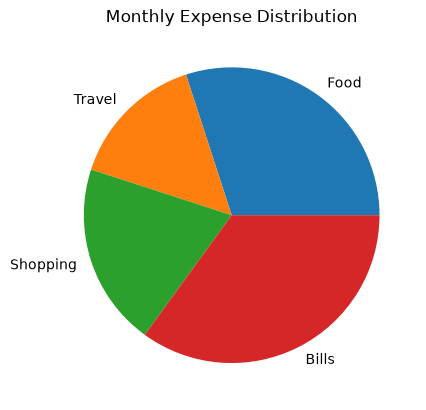

In [2]:
import matplotlib.pyplot as plt

categories = ["Food", "Travel", "Shopping", "Bills"]
expenses = [3000, 1500, 2000, 3500]

plt.pie(expenses, labels=categories)

plt.title("Monthly Expense Distribution")

plt.show()

The main function is plt.pie().

| Parameter | Purpose |
| :--- | :--- |
| expenses | Values that determine the slice sizes |
| labels=categories | Names displayed for each slice |
| plt.title() | Adds a chart title |

Matplotlib calculates each slice's percentage from the total automatically.

## 3. Customize the pie chart
Let's display percentages and separate the Food slice slightly from the center.

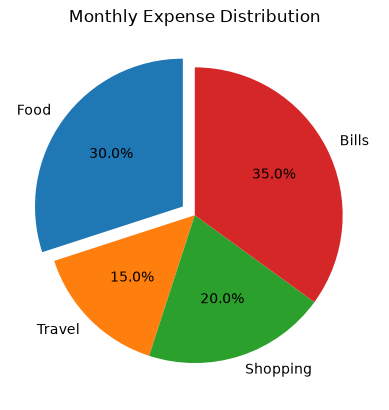

In [3]:
plt.pie(
    expenses,
    labels=categories,
    autopct="%1.1f%%",
    explode=[0.1, 0, 0, 0],
    startangle=90
)

plt.title("Monthly Expense Distribution")

plt.show()

**New parameters:**
- autopct="%1.1f%%" displays percentages to one decimal place.
- explode=[0.1, 0, 0, 0] separates the first slice, Food, from the pie.
- startangle=90 rotates the chart's starting angle.

The explode list corresponds to the order of your categories. Here, only Food is separated.

In [7]:

from IPython.display import HTML, display

display(HTML(r"""
<div id="pie-quiz" style="font-family:Arial,sans-serif;max-width:700px;padding:20px;border:1px solid #ddd;border-radius:12px;">
    <h3>🧠 Predict the Output — Pie Charts</h3>

    <p><b>Q1. What does <code>autopct="%1.1f%%"</code> do?</b></p>
    <label><input type="radio" name="pieq1" value="a"> Displays category names</label><br>
    <label><input type="radio" name="pieq1" value="b"> Displays percentages on the slices</label><br>
    <label><input type="radio" name="pieq1" value="c"> Changes the chart title</label>
    <p id="feedback1"></p>

    <hr>

    <p><b>Q2. What does <code>explode=[0.1, 0, 0, 0]</code> do?</b></p>
    <label><input type="radio" name="pieq2" value="a"> Separates the first slice slightly</label><br>
    <label><input type="radio" name="pieq2" value="b"> Removes the first slice</label><br>
    <label><input type="radio" name="pieq2" value="c"> Makes all slices equal in size</label>
    <p id="feedback2"></p>

    <hr>

    <p><b>Q3. Which expense category occupies the largest slice?</b></p>
    <label><input type="radio" name="pieq3" value="a"> Food</label><br>
    <label><input type="radio" name="pieq3" value="b"> Travel</label><br>
    <label><input type="radio" name="pieq3" value="c"> Bills</label>
    <p id="feedback3"></p>

    <button id="check-pie" style="background:#2563eb;color:white;border:none;padding:10px 18px;border-radius:7px;cursor:pointer;">
        Check Answers
    </button>
    <button id="reset-pie" style="padding:10px 18px;border-radius:7px;cursor:pointer;margin-left:6px;">
        Try Again
    </button>

    <h4 id="pie-score"></h4>
</div>

<script>
(function() {
    const quiz = document.getElementById("pie-quiz");
    if (!quiz || quiz.dataset.initialized) return;
    quiz.dataset.initialized = "true";

    const answers = {pieq1:"b", pieq2:"a", pieq3:"c"};

    quiz.querySelector("#check-pie").addEventListener("click", function() {
        let score = 0;

        for (let i = 1; i <= 3; i++) {
            const name = "pieq" + i;
            const selected = quiz.querySelector(
                'input[name="' + name + '"]:checked'
            );
            const feedback = quiz.querySelector("#feedback" + i);

            if (!selected) {
                feedback.textContent = "Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === answers[name]) {
                score++;
                feedback.textContent = "Correct! ✓";
                feedback.style.color = "green";
            } else {
                feedback.textContent = "Incorrect. Try again!";
                feedback.style.color = "#dc2626";
            }
        }

        quiz.querySelector("#pie-score").textContent =
            "Your score: " + score + " / 3";
    });

    quiz.querySelector("#reset-pie").addEventListener("click", function() {
        quiz.querySelectorAll('input[type="radio"]').forEach(function(input) {
            input.checked = false;
        });

        for (let i = 1; i <= 3; i++) {
            const feedback = quiz.querySelector("#feedback" + i);
            feedback.textContent = "";
        }

        quiz.querySelector("#pie-score").textContent = "";
    });
})();
</script>
"""))


# Part 2 — Box plots
## 1. What is a box plot?
A box plot (also called a box-and-whisker plot) summarizes the distribution of numerical data. It helps you understand the median, spread, quartiles, and potential outliers.
<div align="center">
	<img src="../Images/Box_plot_1.png" style="border-radius: 50px; max-width: 60%;">
</div>

The main parts are:
- Q1 (first quartile): 25% of observations lie at or below this value.
- Median (Q2): The middle of the data; 50% lie at or below it.
- Q3 (third quartile): 75% of observations lie at or below this value.
- Box: Extends from Q1 to Q3, covering the middle 50% of the data.
- Whiskers: Extend to the most extreme data points within the box plot's whisker rule.
- Outliers: Points plotted separately beyond the whiskers.

Important: the whiskers don't necessarily reach the minimum and maximum. Matplotlib's default box plot typically uses the 1.5 × IQR rule.

## 2. Create your first box plot
Let's compare the exam marks of students in two groups.

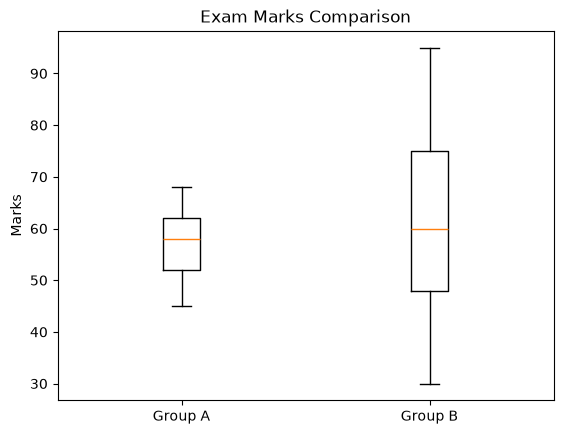

In [10]:
import matplotlib.pyplot as plt

group_a = [45, 50, 52, 55, 58, 60, 62, 65, 68]
group_b = [30, 42, 48, 55, 60, 70, 75, 85, 95]
plt.boxplot([group_a, group_b], tick_labels=["Group A", "Group B"])

plt.title("Exam Marks Comparison")
plt.ylabel("Marks")

plt.show()

If your Matplotlib version doesn't support tick_labels, use labels=["Group A", "Group B"] instead.

What does this chart tell you?
- The line inside each box is the median.
- The box shows the middle 50% of the marks.
- A taller box indicates a wider interquartile range (IQR).
- Whiskers and any separate points help show the spread and potential outliers.

## 3. Customize the box plot
You can style the boxes and show outliers explicitly:

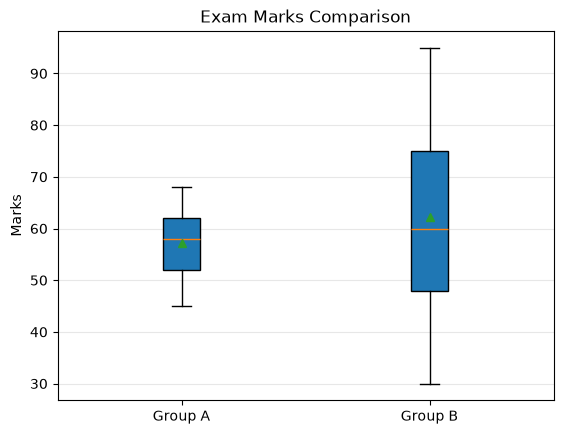

In [11]:
plt.boxplot(
    [group_a, group_b],
    tick_labels=["Group A", "Group B"],
    patch_artist=True,
    showmeans=True,
    flierprops=dict(marker="o", markerfacecolor="red")
)

plt.title("Exam Marks Comparison")
plt.ylabel("Marks")
plt.grid(axis="y", alpha=0.3)

plt.show()

New parameters:
| Parameter | Purpose |
| :--- |:--- |
| patch_artist=True | Allows boxes to be filled with color |
| showmeans=True | Displays the mean as a separate marker |
| flierprops=... | Customizes the appearance of potential outliers |

We'll keep the styling simple for now.

**Detailed explanation of the new parameters**
Let's look at the parameters from your box plot code:

A. patch_artist=True
```text
By default, Matplotlib draws the box outlines without filling the boxes.

Setting patch_artist=True makes the boxes fillable, so you can apply background colors using boxprops.
```
```python
plt.boxplot(
    [group_a, group_b],
    patch_artist=True,
    boxprops=dict(facecolor="lightblue")
)
```
- patch_artist=True: enables filled box patches.
- boxprops: customizes the box appearance.
- facecolor: sets the box's fill color.
```text
You can use colors such as "lightblue", "lightgreen", or "orange".
```
B. showmeans=True
```text
A box plot normally displays the median, but not necessarily the mean.
```
```python
plt.boxplot(group_a, showmeans=True)
```
```text
This adds a separate marker showing the arithmetic mean.
For example, with:
```
```python
data = [10, 20, 30, 40, 100]
```
```text
The mean is **40**, while the median is **30**.

Comparing these two values helps you understand how unusually high or low values affect the average.
```
C. flierprops=dict(...)
```text
Fliers are points plotted beyond the whiskers. They are potential outliers according to the box plot's rule.
```
```python
flierprops=dict(
	marker="o",
	markerfacecolor="red",
	markersize=8
)
```
| Parameter | Meaning |
| :--- | :--- |
| marker="o" | Uses circular markers |
| markerfacecolor="red" | Fills the markers with red |
| markersize=8 | Sets the marker size |
```text
You might use red markers to make potential outliers easier to spot. However, a point outside the whiskers isn't automatically an error; it may be a genuine observation.
```
D. tick_labels=["Group A", "Group B"]
```text
This labels the two box plots on the x-axis.
```
```python
plt.boxplot(
	[group_a, group_b],
	tick_labels=["Group A", "Group B"]
)
```
```text
The first dataset receives the label "Group A", and the second receives "Group B".

Version note: tick_labels is used in newer Matplotlib versions. Older versions use labels instead.
```

In [1]:

from IPython.display import HTML, display

display(HTML(r"""
<div id="box-quiz" style="font-family:Arial,sans-serif;max-width:700px;padding:20px;border:1px solid #ddd;border-radius:12px;">
    <h3>🧠 Predict the Output — Box Plots</h3>

    <p><b>Q1. What does the line inside the box usually represent?</b></p>
    <label><input type="radio" name="boxq1" value="a"> Mean</label><br>
    <label><input type="radio" name="boxq1" value="b"> Median</label><br>
    <label><input type="radio" name="boxq1" value="c"> Maximum</label>
    <p id="boxfeedback1"></p>

    <hr>

    <p><b>Q2. What does the box between Q1 and Q3 represent?</b></p>
    <label><input type="radio" name="boxq2" value="a"> The middle 50% of the data</label><br>
    <label><input type="radio" name="boxq2" value="b"> All data values, without exception</label><br>
    <label><input type="radio" name="boxq2" value="c"> Only the outliers</label>
    <p id="boxfeedback2"></p>

    <hr>

    <p><b>Q3. What does <code>showmeans=True</code> do?</b></p>
    <label><input type="radio" name="boxq3" value="a"> Displays the median only</label><br>
    <label><input type="radio" name="boxq3" value="b"> Hides the whiskers</label><br>
    <label><input type="radio" name="boxq3" value="c"> Displays the mean on the box plot</label>
    <p id="boxfeedback3"></p>

    <br>
    <button id="box-check" style="background:#2563eb;color:white;border:none;padding:10px 18px;border-radius:7px;cursor:pointer;">Check Answers</button>
    <button id="box-reset" style="padding:10px 18px;border-radius:7px;cursor:pointer;margin-left:6px;">Try Again</button>

    <h4 id="box-score"></h4>
</div>

<script>
(function() {
    const quiz = document.getElementById("box-quiz");
    if (!quiz || quiz.dataset.initialized) return;
    quiz.dataset.initialized = "true";

    const answers = {boxq1:"b", boxq2:"a", boxq3:"c"};

    quiz.querySelector("#box-check").addEventListener("click", function() {
        let score = 0;

        for (let i = 1; i <= 3; i++) {
            const name = "boxq" + i;
            const selected = quiz.querySelector(
                'input[name="' + name + '"]:checked'
            );
            const feedback = quiz.querySelector("#boxfeedback" + i);

            if (!selected) {
                feedback.textContent = "Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === answers[name]) {
                score++;
                feedback.textContent = "Correct! ✓";
                feedback.style.color = "green";
            } else {
                feedback.textContent = "Incorrect. Try again!";
                feedback.style.color = "#dc2626";
            }
        }

        quiz.querySelector("#box-score").textContent =
            "Your score: " + score + " / 3";
    });

    quiz.querySelector("#box-reset").addEventListener("click", function() {
        quiz.querySelectorAll('input[type="radio"]').forEach(function(input) {
            input.checked = false;
        });

        for (let i = 1; i <= 3; i++) {
            quiz.querySelector("#boxfeedback" + i).textContent = "";
        }

        quiz.querySelector("#box-score").textContent = "";
    });
})();
</script>
"""))


# Part 3 — Area charts
## 1. What is an area chart?
An area chart is similar to a line plot, but the region below the line is filled with color. It helps emphasize the magnitude of values and how they change over time.

<div>
	<img src="../Images/Area_chart_1.png" style="border-radius: 30px; max-width: 80%;">
</div>

Area charts are useful for:
- Tracking sales or expenses over time.
- Showing how quantities change.
- Comparing contributions to a total using stacked area charts.

## 2. Create your first area chart
Let's visualize monthly sales.

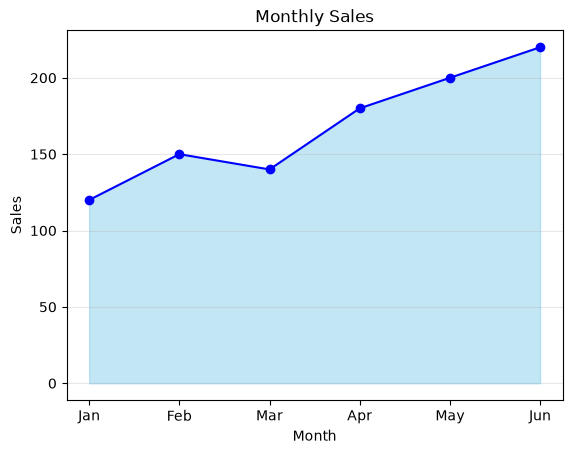

In [2]:
import matplotlib.pyplot as plt

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun"]
sales = [120, 150, 140, 180, 200, 220]

plt.fill_between(months, sales, color="skyblue", alpha=0.5)
plt.plot(months, sales, color="blue", marker="o")

plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(axis="y", alpha=0.3)

plt.show()

**The key function is plt.fill_between().**
| Parameter | Meaning |
| :--- | :--- |
| months | X-axis values |
| sales | Upper boundary of the filled region |
| color="skyblue" | Sets the fill color |
| alpha=0.5 | Makes the fill 50% opaque |

Here, plt.plot() draws the line on top of the filled area, so the data points are easier to see.

## 3. Stacked area charts
A stacked area chart shows how multiple quantities contribute to a combined total over time.

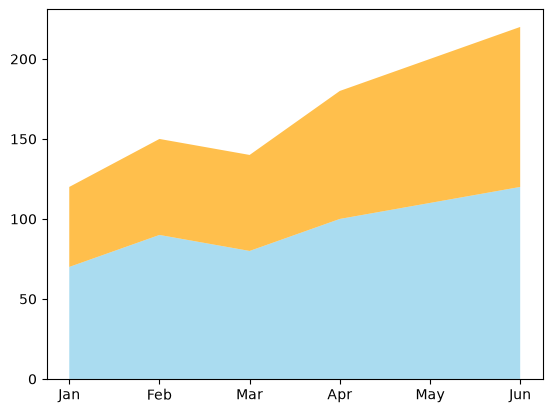

In [3]:
plt.stackplot(
    months,
    [70, 90, 80, 100, 110, 120],
    [50, 60, 60, 80, 90, 100],
    labels=["Product A", "Product B"],
    colors=["skyblue", "orange"],
    alpha=0.7
)

plt.show()

plt.stackplot() stacks the series on top of one another. The height of the full stack represents their combined value for each month.

This is useful when you want to see both the overall trend and each category's contribution.

In [4]:
from IPython.display import HTML, display

display(HTML(r"""
<div id="area-quiz" style="font-family:Arial,sans-serif;max-width:700px;padding:20px;border:1px solid #ddd;border-radius:12px;">
    <h3>🧠 Predict the Output — Area Charts</h3>

    <p><b>Q1. Which function fills the area beneath a line?</b></p>
    <label><input type="radio" name="areaq1" value="a"> plt.scatter()</label><br>
    <label><input type="radio" name="areaq1" value="b"> plt.fill_between()</label><br>
    <label><input type="radio" name="areaq1" value="c"> plt.hist()</label>
    <p id="areafeedback1"></p>

    <hr>

    <p><b>Q2. What does alpha=0.5 mean?</b></p>
    <label><input type="radio" name="areaq2" value="a"> 50% opaque, allowing some background to show through</label><br>
    <label><input type="radio" name="areaq2" value="b"> The fill disappears completely</label><br>
    <label><input type="radio" name="areaq2" value="c"> The line width is halved</label>
    <p id="areafeedback2"></p>

    <hr>

    <p><b>Q3. What does plt.stackplot() help show?</b></p>
    <label><input type="radio" name="areaq3" value="a"> Only the median of a dataset</label><br>
    <label><input type="radio" name="areaq3" value="b"> The distribution of values across bins</label><br>
    <label><input type="radio" name="areaq3" value="c"> How multiple quantities contribute to a total over time</label>
    <p id="areafeedback3"></p>

    <br>
    <button id="area-check" style="background:#2563eb;color:white;border:none;padding:10px 18px;border-radius:7px;cursor:pointer;">Check Answers</button>
    <button id="area-reset" style="padding:10px 18px;border-radius:7px;cursor:pointer;margin-left:6px;">Try Again</button>

    <h4 id="area-score"></h4>
</div>

<script>
(function() {
    const quiz = document.getElementById("area-quiz");
    if (!quiz || quiz.dataset.initialized) return;
    quiz.dataset.initialized = "true";

    const answers = {areaq1:"b", areaq2:"a", areaq3:"c"};

    quiz.querySelector("#area-check").addEventListener("click", function() {
        let score = 0;

        for (let i = 1; i <= 3; i++) {
            const name = "areaq" + i;
            const selected = quiz.querySelector(
                'input[name="' + name + '"]:checked'
            );
            const feedback = quiz.querySelector("#areafeedback" + i);

            if (!selected) {
                feedback.textContent = "Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === answers[name]) {
                score++;
                feedback.textContent = "Correct! ✓";
                feedback.style.color = "green";
            } else {
                feedback.textContent = "Incorrect. Try again!";
                feedback.style.color = "#dc2626";
            }
        }

        quiz.querySelector("#area-score").textContent =
            "Your score: " + score + " / 3";
    });

    quiz.querySelector("#area-reset").addEventListener("click", function() {
        quiz.querySelectorAll('input[type="radio"]').forEach(function(input) {
            input.checked = false;
        });

        for (let i = 1; i <= 3; i++) {
            quiz.querySelector("#areafeedback" + i).textContent = "";
        }

        quiz.querySelector("#area-score").textContent = "";
    });
})();
</script>
"""))

# Day 7 — Final practice: Choose the right chart
In data analysis, it's important not only to create charts but also to choose the right one for the problem.

In [9]:

from IPython.display import HTML, display

display(HTML(r"""
<div id="day7-quiz" style="font-family: Arial, sans-serif; max-width: 700px; line-height: 1.6;">
    <h2>Practice Quiz</h2>
    <p>Select one answer for each question, then click <b>Check Answers</b>.</p>

    <form id="day7-form">
        <fieldset style="margin-bottom: 16px; padding: 12px; border-radius: 8px;">
            <legend><b>Q1.</b> You want to show how four categories contribute to total monthly spending. Which chart is suitable?</legend>
            <label><input type="radio" name="q1" value="A"> A. Pie chart</label><br>
            <label><input type="radio" name="q1" value="B"> B. Box plot</label><br>
            <label><input type="radio" name="q1" value="C"> C. Area chart</label>
        </fieldset>

        <fieldset style="margin-bottom: 16px; padding: 12px; border-radius: 8px;">
            <legend><b>Q2.</b> You want to compare exam score distributions and identify potential outliers. Which chart should you use?</legend>
            <label><input type="radio" name="q2" value="A"> A. Pie chart</label><br>
            <label><input type="radio" name="q2" value="B"> B. Box plot</label><br>
            <label><input type="radio" name="q2" value="C"> C. Area chart</label>
        </fieldset>

        <fieldset style="margin-bottom: 16px; padding: 12px; border-radius: 8px;">
            <legend><b>Q3.</b> You want to show how three products contribute to total sales each month. Which chart is most suitable?</legend>
            <label><input type="radio" name="q3" value="A"> A. Pie chart</label><br>
            <label><input type="radio" name="q3" value="B"> B. Box plot</label><br>
            <label><input type="radio" name="q3" value="C"> C. Stacked area chart</label>
        </fieldset>

        <fieldset style="margin-bottom: 16px; padding: 12px; border-radius: 8px;">
            <legend><b>Q4.</b> You want to visualize one product's sales from January to June, emphasizing the amount over time. Which chart is suitable?</legend>
            <label><input type="radio" name="q4" value="A"> A. Area chart</label><br>
            <label><input type="radio" name="q4" value="B"> B. Box plot</label><br>
            <label><input type="radio" name="q4" value="C"> C. Pie chart</label>
        </fieldset>

        <button type="button" id="day7-check"
            style="padding: 10px 18px; background: #2563eb; color: white; border: none; border-radius: 6px; cursor: pointer;">
            Check Answers
        </button>
        <button type="button" id="day7-reset"
            style="padding: 10px 18px; margin-left: 8px; border: 1px solid #aaa; border-radius: 6px; cursor: pointer;">
            Reset
        </button>
    </form>

    <div id="day7-result" aria-live="polite"
         style="margin-top: 16px; font-weight: bold;"></div>
</div>

<script>
(function () {
    const root = document.getElementById("day7-quiz");
    if (!root || root.dataset.initialized === "true") return;
    root.dataset.initialized = "true";

    const answers = {q1: "A", q2: "B", q3: "C", q4: "A"};
    const explanations = {
        q1: "A — A pie chart shows how categories make up a whole.",
        q2: "B — A box plot compares distributions and can reveal potential outliers.",
        q3: "C — A stacked area chart shows each product's contribution over time.",
        q4: "A — An area chart emphasizes the amount changing over time."
    };

    root.querySelector("#day7-check").addEventListener("click", function () {
        let score = 0;
        let feedback = "";

        for (const question in answers) {
            const selected = root.querySelector(
                'input[name="' + question + '"]:checked'
            );

            if (selected && selected.value === answers[question]) {
                score++;
                feedback += "<p style='color: #15803d;'>✓ " +
                    explanations[question] + "</p>";
            } else {
                feedback += "<p style='color: #b91c1c;'>✗ " +
                    question.toUpperCase() + ": Correct answer — " +
                    explanations[question] + "</p>";
            }
        }

        root.querySelector("#day7-result").innerHTML =
            "<h3>Your score: " + score + "/4</h3>" + feedback;
    });

    root.querySelector("#day7-reset").addEventListener("click", function () {
        root.querySelector("#day7-form").reset();
        root.querySelector("#day7-result").innerHTML = "";
    });
})();
</script>
"""))
